# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "S31/clients.csv"
RAW_TXN = "S31/transactions.csv"

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [2]:
# DataFrame — таблица: строки — записи, столбцы — признаки.
# Идентификаторы читаем строками, чтобы сохранить ведущие нули.
clients_raw = pd.read_csv(RAW_CLIENTS, encoding="utf-8-sig", dtype="string")
txn_raw = pd.read_csv(RAW_TXN, encoding="cp1251", sep=";", dtype="string")
# Пока всё хранится как текст: преобразования сделаем после аудита.
print("Клиенты (строки, столбцы):", clients_raw.shape)
print("Операции (строки, столбцы):", txn_raw.shape)
display(clients_raw.head())
display(txn_raw.head())


Клиенты (строки, столбцы): (5696, 16)
Операции (строки, столбцы): (613095, 9)


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C001762,1973-09-17,Ж,казань,Массовый,Базовый,Дебетовая,29.12.2018,22.07.2023,Зарплата в другом банке,74200.0,Да,2024-06,4,00573,Да
1,C003583,1974-02-22,М,казань,Зарплатный,Базовый,Дебетовая,29.09.2016,07.03.2021,Зарплата в другом банке,76000.0,Да,2024-05,<NA>,00316,Да
2,C004742,1968-08-09,М,Москва,Private,Платина,Дебетовая,24.05.2016,12.01.2019,Зарплата в нашем банке,338400.0,Да,2024-04,2,00226,Да
3,C005442,1965-10-08,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,04.02.2020,01.07.2021,Зарплата в нашем банке,150100.0,Нет,<NA>,<NA>,00497,Да
4,C003493,1990-08-29,Ж,Казань,Массовый,Золото,Дебетовая,24.04.2022,08.10.2022,Зарплата в нашем банке,32300.0,Нет,<NA>,<NA>,00112,Нет


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990071,C003817,2023-11-26 15:21:53,"3190,05",RUB,Развлечения и досуг,7832,Токен,успешно
1,990033,C003658,2023-12-01 16:30:04,"2443,25",RUB,Продукты,5411,Карта,успешно
2,990141,C003289,2023-12-05 15:28:48,"161,38",RUB,Транспорт,4111,Онлайн-банк,успешно
3,990053,C001662,2023-12-09,"1042,76",RUB,Продукты,5411,СБП,отклонено
4,990084,C004074,2023-12-10,"1012,69",RUB,Развлечения и досуг,7832,Токен,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [3]:
# В справочнике ожидается одна строка на клиента, в операциях — на операцию.
for name, df, key in [("Клиенты", clients_raw, "client_id"),
                      ("Операции", txn_raw, "txn_id")]:
    print(name)
    print("Строк:", len(df), "Уникальных ключей:", df[key].nunique())
    print("Пропущенных ключей:", df[key].isna().sum())
    display(df.dtypes.to_frame("тип после загрузки"))
    # Знаменатель доли пропусков — все строки соответствующей таблицы.
    display(pd.DataFrame({"пропущено": df.isna().sum(),
                          "доля, %": df.isna().mean() * 100}))


Клиенты
Строк: 5696 Уникальных ключей: 5641
Пропущенных ключей: 0


,тип после загрузки
client_id,string
birth_date,string
gender,string
city,string
segment,string
loyalty_tier,string
card_type,string
registration_date,string
card_open_date,string
income_source,string


,пропущено,"доля, %"
client_id,0,0.000000
birth_date,0,0.000000
gender,0,0.000000
city,0,0.000000
segment,0,0.000000
loyalty_tier,0,0.000000
card_type,0,0.000000
registration_date,0,0.000000
card_open_date,0,0.000000
income_source,0,0.000000


Операции
Строк: 613095 Уникальных ключей: 611595


Пропущенных ключей: 0


,тип после загрузки
txn_id,string
client_id,string
txn_datetime,string
amount,string
currency,string
category,string
mcc_code,string
channel,string
status,string


,пропущено,"доля, %"
txn_id,0,0.0
client_id,0,0.0
txn_datetime,0,0.0
amount,0,0.0
currency,0,0.0
category,0,0.0
mcc_code,0,0.0
channel,0,0.0
status,0,0.0


### 2.2. Дубли

In [4]:
for name, df, key in [("Клиенты", clients_raw, "client_id"),
                      ("Операции", txn_raw, "txn_id")]:
    print(name)
    print("Лишних точных копий:", df.duplicated().sum())
    distinct = df.drop_duplicates()  # Временная таблица только для диагностики.
    conflict = distinct[key].duplicated(keep=False)
    print("Ключей с разными версиями записи:", distinct.loc[conflict, key].nunique())
    display(distinct.loc[conflict].sort_values(key).head(10))
# Исходные таблицы не изменены. Конфликтующие записи нельзя удалять вслепую.


Клиенты
Лишних точных копий: 41
Ключей с разными версиями записи: 14


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
5681,C000389,1987-02-26,Ж,Екатеринбург,Private,Платина,Кредитная,26.07.2016,16.08.2016,Зарплата в другом банке,499500.0,Да,2024-02,4,00848,Да
2884,C000389,1987-02-26,Ж,Новосибирск,Private,Платина,Кредитная,26.07.2016,16.08.2016,Зарплата в другом банке,499500.0,Да,2024-02,4,00848,Да
201,C002114,1953-11-25,Ж,Москва,Массовый,Золото,Дебетовая,14.06.2015,23.04.2017,Не указан,247800.0,Да,2025-05,5,00520,Да
2204,C002114,1953-11-25,Ж,Нижний Новгород,Премиальный,Золото,Дебетовая,14.06.2015,23.04.2017,Не указан,247800.0,Да,2025-05,5,00520,Да
164,C002190,1974-03-06,М,Новосибирск,Премиальный,Базовый,Дебетовая,03.04.2017,21.11.2021,Не указан,<NA>,Нет,<NA>,<NA>,00738,Нет
678,C002190,1974-03-06,М,Казань,Массовый,Базовый,Дебетовая,03.04.2017,21.11.2021,Не указан,<NA>,Нет,<NA>,<NA>,00738,Нет
3630,C003666,1959-07-02,М,Новосибирск,Зарплатный,Базовый,Дебетовая,30.11.2013,23.02.2016,Не указан,61700.0,Нет,<NA>,<NA>,00678,Да
911,C003666,1959-07-02,М,Екатеринбург,Массовый,Базовый,Дебетовая,30.11.2013,23.02.2016,Не указан,61700.0,Нет,<NA>,<NA>,00678,Да
939,C003996,1966-07-07,М,Казань,Зарплатный,Золото,Дебетовая,07.04.2020,14.10.2023,Зарплата в другом банке,212900.0,Да,2024-08,2,00527,Да
3318,C003996,1966-07-07,М,Н. Новгород,Премиальный,Золото,Дебетовая,07.04.2020,14.10.2023,Зарплата в другом банке,212900.0,Да,2024-08,2,00527,Да


Операции


Лишних точных копий: 1283


Ключей с разными версиями записи: 217


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
1373,101363,C002026,2024-01-02,"1570,2",RUB,Онлайн-сервисы,5815,СБП,успешно
1374,101363,C002026,2024-01-02 21:25:09,"1570,2",RUB,Онлайн-сервисы,5815,СБП,успешно
4741,104719,C003454,2024-01-06 12:49:25,"383,06",RUB,Кафе/рестораны,5812,Карта,успешно
4742,104719,C003454,2024-01-06,"383,06",RUB,Кафе/рестораны,5812,Карта,успешно
7032,107004,C001053,2024-01-08,"2713,95",RUB,АЗС,5541,Токен,успешно
7033,107004,C001053,2024-01-08 14:31:39,"2713,95",RUB,АЗС,5541,Токен,успешно
7360,107330,C001119,2024-01-08,"472,15",RUB,Кафе и рестораны,5812,Токен,успешно
7361,107330,C001119,2024-01-08 21:26:53,"472,15",RUB,Кафе и рестораны,5812,Токен,успешно
19708,119658,C005602,2024-01-23,"621,58",RUB,Продукты,5411,Карта,успешно
19709,119658,C005602,2024-01-23 11:16:36,"621,58",RUB,Продукты,5411,Карта,успешно


### 2.3. Соответствие данных описанию полей из задания

In [5]:
for column in ["city", "segment", "has_mobile_app", "marketing_opt_in"]:
    display(clients_raw[column].value_counts(dropna=False).to_frame("число строк"))
for column in ["currency", "status", "channel", "category"]:
    display(txn_raw[column].value_counts(dropna=False).to_frame("число строк"))
dates = pd.to_datetime(txn_raw["txn_datetime"], format="mixed", errors="coerce")
print("Фактические границы дат:", dates.min(), dates.max())
print("Не распознаны даты:", dates.isna().sum())
in_period = dates.ge("2024-01-01") & dates.lt("2025-07-01")
print("Распознанные даты вне периода:", (dates.notna() & ~in_period).sum())


,число строк
city,
Москва,1115
Казань,692
Санкт-Петербург,679
Нижний Новгород,574
Новосибирск,509
Екатеринбург,503
казань,211
МОСКВА,197
москва,172


,число строк
segment,
Массовый,2899
Зарплатный,1681
Премиальный,901
Private,215


,число строк
has_mobile_app,
Да,3544
Нет,2152


,число строк
marketing_opt_in,
Да,5004
Нет,692


,число строк
currency,
RUB,610619
EUR,1242
USD,1234


,число строк
status,
успешно,593758
отклонено,12129
возврат,7208


,число строк
channel,
Карта,315913
СБП,107840
Токен,98893
Онлайн-банк,90449


,число строк
category,
Продукты,162516
Транспорт,70006
Одежда и обувь,63344
АЗС,56597
Кафе и рестораны,47370
Развлечения и досуг,46358
Аптеки,44917
Онлайн-сервисы,42707
Связь и интернет,28766


Фактические границы дат: 2023-11-26 15:21:53 2026-07-28 12:47:34
Не распознаны даты: 0
Распознанные даты вне периода: 94


### 2.4. Связь между таблицами

In [6]:
unknown = ~txn_raw["client_id"].isin(clients_raw["client_id"])
print("Операций без клиента в справочнике:", unknown.sum())
print("Доля от всех операций, %:", unknown.mean() * 100)
print("Клиентов без операций:",
      clients_raw.loc[~clients_raw["client_id"].isin(txn_raw["client_id"]), "client_id"].nunique())


Операций без клиента в справочнике: 30265
Доля от всех операций, %: 4.936429101525865
Клиентов без операций: 8


**Выводы по аудиту.**

- В сыром справочнике 5696 строк и 5641 уникальный клиент; в операциях 613095 строк и 611595 уникальных идентификаторов операций.
- Найдены 41 лишняя полная копия строки клиента и 1283 лишние полные копии операций.
- После удаления полных копий у 14 клиентов остаются разные версии записи: город различается у 14, сегмент — у 11; другие поля совпадают. Нельзя произвольно выбирать актуальную версию.
- У 217 операций остаются две версии: дата без времени и тот же день с временем; остальные поля совпадают. При очистке можно сохранить более подробную версию.
- Все даты операций распознаны. 94 строки находятся вне заявленного периода: 10 до 2024-01-01 и 84 начиная с 2025-07-01. Они не должны участвовать в расчёте активности за период задания.
- 30265 из 613095 строк операций ссылаются на 359 идентификаторов, отсутствующих в справочнике. Причина отсутствия неизвестна. У 8 уникальных клиентов справочника нет записей в сырой таблице операций.
- Пропуски в справочнике: доход — 508 из 5696 строк, последний вход в приложение — 2152 из 5696, оценка удовлетворённости — 3411 из 5696. Механизмы пропусков исследуются отдельно; автоматически заполнять их нельзя.
- Есть варианты написания городов и категорий, несколько валют и статусов операций. Необходимо нормализовать категории и явно определить фильтры метрики.

На этом этапе исходные таблицы не изменялись. Количества относятся к сырой выгрузке, кроме явно указанных проверок после удаления полных копий.


## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### Начало очистки: рабочие копии и полные дубликаты
Исходные таблицы сохраняем. Пока удаляем только строки, совпадающие по всем полям. Разные версии одного идентификатора обрабатываются отдельно.

In [7]:
# Работаем с копиями: сырые таблицы нужны для проверки изменений.
clients = clients_raw.copy()
txn = txn_raw.copy()

# Журнал создаём ДО очистки, чтобы фиксировать решения по ходу работы.
log_rows = []

def log_change(field, issue, scope, n_rows, value_before,
               action, value_after, rationale):
    log_rows.append({
        "field": field, "issue": issue, "scope": scope,
        "n_rows": int(n_rows), "value_before": value_before,
        "action": action, "value_after": value_after,
        "rationale": rationale,
    })

# Удаляем только полностью одинаковые строки.
for name, table in [("clients", clients), ("transactions", txn)]:
    n_duplicates = table.duplicated().sum()
    log_change(
        name, "Полные дубликаты", "Все поля строки совпадают",
        n_duplicates, len(table), "Удалены лишние полные копии",
        len(table) - n_duplicates,
        "Повторная копия не является отдельным клиентом или операцией",
    )

clients = clients.drop_duplicates().copy()
txn = txn.drop_duplicates().copy()
print("После удаления полных копий:", len(clients), "строк клиентов;",
      len(txn), "строк операций")


После удаления полных копий: 5655 строк клиентов; 611812 строк операций


### 3.1. Типы, даты, числа

In [8]:
# 1. Преобразуем даты. Нераспознанные значения станут NaT.
for column, date_format in [
    ("birth_date", "%Y-%m-%d"),
    ("registration_date", "%d.%m.%Y"),
    ("card_open_date", "%d.%m.%Y"),
    ("app_last_login", "%Y-%m"),
]:
    before = clients[column].copy()
    clients[column] = pd.to_datetime(before, format=date_format, errors="coerce")
    invalid = before.notna() & clients[column].isna()
    log_change(column, "Дата хранится текстом", "Непустые значения clients",
               before.notna().sum(), "string", "Преобразование типа",
               f"datetime; не распознано: {invalid.sum()}",
               "Для сравнения дат и вычисления возраста нужны даты, а не строки")
    print(column, "не распознано:", invalid.sum())

# Сохраняем признак наличия времени до преобразования:
# дата без времени после преобразования получила бы искусственное 00:00:00.
txn["has_time"] = txn["txn_datetime"].str.contains(":", na=False)
before = txn["txn_datetime"].copy()
txn["txn_datetime"] = pd.to_datetime(before, format="mixed", errors="coerce")
log_change("txn_datetime", "Смешанная точность даты и времени",
           "Непустые значения transactions", before.notna().sum(), "string",
           "Преобразование типа", "datetime; точность сохранена в has_time",
           "Для отбора периода; отсутствие времени не означает операцию в полночь")
print("txn_datetime, не распознано:",
      (before.notna() & txn["txn_datetime"].isna()).sum())

# 2. Преобразуем числа. В суммах операций десятичный разделитель — запятая.
for table_name, table, column in [
    ("clients", clients, "monthly_income"),
    ("clients", clients, "satisfaction_score"),
    ("transactions", txn, "amount"),
]:
    before = table[column].copy()
    table[column] = pd.to_numeric(before.str.replace(",", ".", regex=False), errors="coerce")
    invalid = before.notna() & table[column].isna()
    log_change(column, "Число хранится текстом", f"Непустые значения {table_name}",
               before.notna().sum(), "string", "Преобразование типа",
               f"Число; не распознано: {invalid.sum()}",
               "Необходимо для числовых сравнений и статистик")
    print(column, "не распознано:", invalid.sum())

# 3. Проверяем, что повторные txn_id различаются только точностью времени.
repeated = txn.loc[txn["txn_id"].duplicated(keep=False)].copy()
other_fields = [c for c in txn.columns
                if c not in ["txn_id", "txn_datetime", "has_time"]]
assert repeated.groupby("txn_id")[other_fields].nunique(dropna=False).le(1).all().all()
assert repeated["txn_datetime"].notna().all()
assert repeated.assign(day=repeated["txn_datetime"].dt.normalize()).groupby(
    "txn_id")["day"].nunique().eq(1).all()
assert repeated.groupby("txn_id").size().eq(2).all()
assert repeated.groupby("txn_id")["has_time"].sum().eq(1).all()

# Сначала записи с временем: drop_duplicates оставит первую версию каждого ID.
n_before = len(txn)
txn = txn.sort_values("has_time", ascending=False, kind="stable").drop_duplicates(
    "txn_id", keep="first").copy()
log_change("txn_id / txn_datetime", "Повтор операции с отсутствующим временем",
           "Повторные txn_id: тот же день, остальные поля совпадают",
           n_before - len(txn), "Две версии операции", "Удалена версия без времени",
           "Одна версия с временем", "Сохраняем более подробную запись без двойного учёта")
print("Удалено версий без времени:", n_before - len(txn))
print("Осталось операций:", len(txn))


birth_date не распознано: 0
registration_date не распознано: 0
card_open_date не распознано: 0
app_last_login не распознано: 0


txn_datetime, не распознано: 0
monthly_income не распознано: 0
satisfaction_score не распознано: 0


amount не распознано: 0


Удалено версий без времени: 217
Осталось операций: 611595


### 3.2. Категориальные признаки

In [9]:
# Нормализуем только известные варианты написания одного города.
city_map = {"москва": "Москва", "г. москва": "Москва",
    "казань": "Казань", "санкт-петербург": "Санкт-Петербург",
    "санкт петербург": "Санкт-Петербург", "спб": "Санкт-Петербург",
    "г. санкт-петербург": "Санкт-Петербург", "нижний новгород": "Нижний Новгород",
    "н. новгород": "Нижний Новгород", "новосибирск": "Новосибирск",
    "г. новосибирск": "Новосибирск", "екатеринбург": "Екатеринбург",
    "г.екатеринбург": "Екатеринбург"}
before = clients["city"].copy()
clients["city"] = before.str.strip().str.lower().map(city_map).fillna(before)
log_change("city", "Варианты написания", "Известные варианты city", (before != clients.city).sum(),
           "Регистр, пробелы, сокращения", "Нормализация", "Единые названия", "Смысл города не меняется")

# Если версии клиента противоречат друг другу, сохраняем клиента,
# но не используем спорное поле как достоверный признак.
for column in ["city", "segment"]:
    counts = clients.groupby("client_id")[column].nunique(dropna=False)
    ids = counts[counts > 1].index
    mask = clients.client_id.isin(ids)
    clients[column + "_conflict"] = mask
    log_change(column, "Разные версии поля одного клиента", "ID с несколькими значениями после нормализации",
               mask.sum(), "Противоречащие значения", "Заменено на неизвестное",
               "Неизвестно (конфликт)", "Нет даты актуальности; сохраняем клиента без произвольного выбора версии")
    clients.loc[mask, column] = "Неизвестно (конфликт)"
n_before = len(clients)
clients = clients.drop_duplicates().copy()
assert clients.client_id.is_unique
log_change("client_id", "Совпавшие версии после обработки конфликтов", "Полные копии после нормализации",
           n_before-len(clients), n_before, "Объединены версии", len(clients), "Одна строка на клиента")

category_map = {"Кафе/рестораны": "Кафе и рестораны",
                "кафе и рестораны": "Кафе и рестораны", "Связь и Интернет": "Связь и интернет"}
before = txn.category.copy()
txn["category"] = before.replace(category_map)
log_change("category", "Варианты написания", "Три известных варианта category",
           (before != txn.category).sum(), "Разные написания", "Нормализация",
           "9 категорий", "Объединяем только одинаковый смысл")

# Проверка согласованности MCC и категории: наиболее частое соответствие —
# диагностический ориентир, а не доказательство правильности конкретной строки.
mcc_reference = txn.groupby("mcc_code")["category"].agg(lambda s: s.mode().iloc[0])
txn["category_mcc_conflict"] = txn.category.ne(txn.mcc_code.map(mcc_reference))
print("Строк с нетипичным сочетанием MCC и категории:", txn.category_mcc_conflict.sum())
log_change("category / mcc_code", "Нетипичное сочетание", "Отклонение от модальной категории MCC",
           txn.category_mcc_conflict.sum(), "Два источника категории", "Оставлено с флагом",
           "Исходная категория сохранена", "Нет основания считать MCC или category безусловно правильным")
print("Уникальных клиентов:", len(clients))
display(clients.city.value_counts())


Строк с нетипичным сочетанием MCC и категории: 1697
Уникальных клиентов: 5641


city
Москва                   1631
Санкт-Петербург           999
Казань                    891
Нижний Новгород           723
Екатеринбург              719
Новосибирск               665
Неизвестно (конфликт)      13
Name: count, dtype: int64

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [10]:
# Доля пропусков после объединения версий: знаменатель — уникальные клиенты.
missing_summary = pd.DataFrame({"n_missing": clients.isna().sum(),
                               "pct_missing": clients.isna().mean() * 100})
display(missing_summary.loc[missing_summary.n_missing > 0])

# Проверяем возможные механизмы, а не объявляем их доказанными.
display(pd.crosstab(clients.has_mobile_app, clients.app_last_login.isna(),
                    rownames=["Приложение"], colnames=["Нет даты входа"]))
for field in ["monthly_income", "satisfaction_score"]:
    print("Доля пропусков по сегментам:", field)
    display(clients.assign(missing=clients[field].isna()).groupby("segment").agg(
        n_clients=("client_id", "size"), missing_pct=("missing", lambda s: s.mean()*100)))
# Доход и удовлетворённость не нужны для основной метрики: не придумываем значения.
for field in ["monthly_income", "satisfaction_score", "app_last_login"]:
    log_change(field, "Пропуски", "Клиенты с отсутствующим значением", clients[field].isna().sum(),
               "Пропуск", "Оставлено", "Пропуск", "Нет надёжного основания для заполнения; не заменяем неизвестное нулём")


,n_missing,pct_missing
monthly_income,502,8.899131
app_last_login,2132,37.794717
satisfaction_score,3386,60.024818


Нет даты входа,False,True
Приложение,,
Да,3509,0
Нет,0,2132


Доля пропусков по сегментам: monthly_income


,n_clients,missing_pct
segment,,
Private,210,8.095238
Зарплатный,1668,4.676259
Массовый,2870,11.707317
Неизвестно (конфликт),11,9.090909
Премиальный,882,7.936508


Доля пропусков по сегментам: satisfaction_score


,n_clients,missing_pct
segment,,
Private,210,34.285714
Зарплатный,1668,60.611511
Массовый,2870,65.087108
Неизвестно (конфликт),11,36.363636
Премиальный,882,48.866213


**Выводы о пропусках (5641 уникальный клиент, до обработки некорректного дохода в 3.4).**

- `app_last_login`: 2132 пропуска (37,79%). Все они относятся к клиентам без приложения; у 3509 клиентов с приложением дата заполнена. Это структурное отсутствие признака, а не основание подставлять дату или ноль.
- `monthly_income`: 502 пропуска (8,90%). В массовом сегменте доля составляет 11,71%, в зарплатном — 4,68%. Наблюдается связь с сегментом; механизм MAR (зависимость от наблюдаемых признаков) возможен, но не доказан. Также нельзя исключить MNAR: вероятность раскрытия дохода может зависеть от самого дохода. Значения не заполняем.
- `satisfaction_score`: 3386 пропусков (60,02%). В массовом сегменте пропущено 65,09%, в Private — 34,29%. Возможны различия в охвате опросом и склонности отвечать. Без сведений о приглашениях нельзя отличить отсутствие опроса от отказа; нельзя исключить зависимость ответа от удовлетворённости (MNAR). Не заполняем и не распространяем оценки ответивших на всех клиентов.
- Неизвестный конфликтующий сегмент — отдельная небольшая группа (11 клиентов), её проценты не интерпретируем как устойчивую закономерность.
- После замены отрицательных доходов на пропуски в 3.4 число отсутствующих значений дохода увеличится. Приведённые выше числа описывают состояние на шаге 3.3.


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [11]:
# Обнаружение: межквартильный размах (IQR) — статистический ориентир,
# а не автоматическое основание удалить наблюдение.
for field, series in [("monthly_income", clients.monthly_income),
                      ("amount успешных операций", txn.loc[txn.status.eq("успешно"), "amount"])]:
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3-q1
    unusual = series.lt(q1-1.5*iqr) | series.gt(q3+1.5*iqr)
    print(field, "границы IQR:", round(q1-1.5*iqr, 2), round(q3+1.5*iqr, 2),
          "за границами:", unusual.sum(), "из", series.notna().sum())
    display(series.describe(percentiles=[.01, .25, .5, .75, .99]))
    log_change(field, "Статистические крайние значения", "Значения за границами 1.5 IQR на шаге 3.4",
               unusual.sum(), f"Границы: {q1-1.5*iqr:.2f}; {q3+1.5*iqr:.2f}", "Оставлено",
               "Без статистического отсечения", "Крайнее значение не доказывает ошибку; некорректный отрицательный доход обрабатывается отдельно")

display(pd.crosstab(txn.status, txn.amount.le(0)))
# Отрицательный месячный доход противоречит трактовке этого поля как дохода.
invalid_income = clients.monthly_income.lt(0).fillna(False)
log_change("monthly_income", "Отрицательный доход", "monthly_income < 0", invalid_income.sum(),
           str(clients.loc[invalid_income, "monthly_income"].unique()), "Заменено пропуском",
           "NA", "Некорректное значение; истинный доход неизвестен")
clients.loc[invalid_income, "monthly_income"] = pd.NA
clients["age"] = (pd.Timestamp("2025-06-30")-clients.birth_date).dt.days/365.2425
clients["age_suspect"] = (clients.age.lt(18) | clients.age.gt(100)).fillna(True)
clients["date_order_suspect"] = (clients.registration_date.gt(clients.card_open_date)
    | clients.card_open_date.gt("2025-06-30") | clients.registration_date.gt("2025-06-30"))
print("Возраст требует проверки:", clients.age_suspect.sum())
print("Порядок дат требует проверки:", clients.date_order_suspect.sum())
print("Доход от 0 до 1000 рублей, требует проверки:", clients.monthly_income.between(0, 1000).sum())


monthly_income границы IQR: -29875.0 189525.0 за границами: 426 из 5139


count          5139.0
mean     93309.959058
std      78106.554483
min            -999.0
1%             -999.0
25%           52400.0
50%           72800.0
75%          107250.0
99%          418248.0
max         1154700.0
Name: monthly_income, dtype: Float64

amount успешных операций границы IQR: -2153.33 4832.41 за границами: 47647 из 592295


count       592295.0
mean     1841.410773
std      2556.868875
min             0.08
1%             29.93
25%           466.32
50%          1052.98
75%         2212.755
99%       12197.6248
max        207481.45
Name: amount, dtype: Float64

amount,False,True
status,,
возврат,0,7199
отклонено,12101,0
успешно,592295,0


Возраст требует проверки:

 0
Порядок дат требует проверки: 0
Доход от 0 до 1000 рублей, требует проверки: 168


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [12]:
# Основная метрика: количество успешных операций в месяц, во всех валютах.
# Суммы разных валют не складываем. Возврат не считается новой покупкой.
# Согласие на маркетинг проверим при отборе кампании, не при описании клиентов.
activity_txn = txn.copy()
funnel_rows = [{"step": "После устранения дубликатов", "n_rows": len(activity_txn), "removed": 0}]
filters = [
    ("Клиент есть в справочнике", lambda d: d.client_id.isin(clients.client_id),
     "Без справочника неизвестны признаки клиента и согласие"),
    ("Дата внутри периода", lambda d: d.txn_datetime.ge("2024-01-01") & d.txn_datetime.lt("2025-07-01"),
     "Исследуем только заданное окно"),
    ("Успешная операция", lambda d: d.status.eq("успешно"),
     "Отклонения и возвраты не считаем успешной покупкой"),
    ("Положительная сумма", lambda d: d.amount.gt(0).fillna(False),
     "Основная метрика считает положительные успешные операции"),
]
for step, rule, reason in filters:
    keep = rule(activity_txn)
    removed = (~keep).sum()
    log_change("activity_txn", step, "Последовательная фильтрация: " + step,
               removed, len(activity_txn), "Исключено из расчёта активности",
               int(keep.sum()), reason)
    activity_txn = activity_txn.loc[keep].copy()
    funnel_rows.append({"step": step, "n_rows": len(activity_txn), "removed": int(removed)})
funnel = pd.DataFrame(funnel_rows)
display(funnel)
assert clients.client_id.is_unique
assert activity_txn.txn_id.is_unique
# Сохраняем всех клиентов. Нулевую активность учтём при построении месячной таблицы.
print("Клиентов без успешных операций в периоде:",
      (~clients.client_id.isin(activity_txn.client_id)).sum())


,step,n_rows,removed
0,После устранения дубликатов,611595,0
1,Клиент есть в справочнике,581409,30186
2,Дата внутри периода,581320,89
3,Успешная операция,562973,18347
4,Положительная сумма,562973,0


Клиентов без успешных операций в периоде: 10


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [13]:
# Каждая запись log_rows — одно решение, добавленное при очистке.
log_columns = [
    "field", "issue", "scope", "n_rows", "value_before",
    "action", "value_after", "rationale",
]
cleaning_log = pd.DataFrame(log_rows, columns=log_columns)

# Проверяем обязательные поля и корректность количества затронутых строк.
assert not cleaning_log.empty, "Журнал пуст: сначала выполните раздел 3"
assert cleaning_log[log_columns].notna().all().all(), "В журнале есть незаполненные поля"
assert cleaning_log["n_rows"].ge(0).all(), "Количество строк не может быть отрицательным"

# Полный журнал для проверки и сдачи.
with pd.option_context("display.max_rows", None, "display.max_colwidth", 100):
    display(cleaning_log)

cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8-sig")
print("Сохранён cleaning_log.csv. Записей о решениях:", len(cleaning_log))

# Краткий обзор действий. Число решений — не число изменённых строк.
display(cleaning_log.groupby("action", sort=False).size().to_frame("n_decisions"))
# n_rows нельзя суммировать как число уникальных изменённых записей:
# одна строка данных могла пройти несколько преобразований.


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,clients,Полные дубликаты,Все поля строки совпадают,41,5696,Удалены лишние полные копии,5655,Повторная копия не является отдельным клиентом или операцией
1,transactions,Полные дубликаты,Все поля строки совпадают,1283,613095,Удалены лишние полные копии,611812,Повторная копия не является отдельным клиентом или операцией
2,birth_date,Дата хранится текстом,Непустые значения clients,5655,string,Преобразование типа,datetime; не распознано: 0,"Для сравнения дат и вычисления возраста нужны даты, а не строки"
3,registration_date,Дата хранится текстом,Непустые значения clients,5655,string,Преобразование типа,datetime; не распознано: 0,"Для сравнения дат и вычисления возраста нужны даты, а не строки"
4,card_open_date,Дата хранится текстом,Непустые значения clients,5655,string,Преобразование типа,datetime; не распознано: 0,"Для сравнения дат и вычисления возраста нужны даты, а не строки"
5,app_last_login,Дата хранится текстом,Непустые значения clients,3518,string,Преобразование типа,datetime; не распознано: 0,"Для сравнения дат и вычисления возраста нужны даты, а не строки"
6,txn_datetime,Смешанная точность даты и времени,Непустые значения transactions,611812,string,Преобразование типа,datetime; точность сохранена в has_time,Для отбора периода; отсутствие времени не означает операцию в полночь
7,monthly_income,Число хранится текстом,Непустые значения clients,5152,string,Преобразование типа,Число; не распознано: 0,Необходимо для числовых сравнений и статистик
8,satisfaction_score,Число хранится текстом,Непустые значения clients,2265,string,Преобразование типа,Число; не распознано: 0,Необходимо для числовых сравнений и статистик
9,amount,Число хранится текстом,Непустые значения transactions,611812,string,Преобразование типа,Число; не распознано: 0,Необходимо для числовых сравнений и статистик


Сохранён cleaning_log.csv. Записей о решениях: 27


,n_decisions
action,
Удалены лишние полные копии,2
Преобразование типа,8
Удалена версия без времени,1
Нормализация,2
Заменено на неизвестное,2
Объединены версии,1
Оставлено с флагом,1
Оставлено,5
Заменено пропуском,1


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

,count,mean,std,min,25%,50%,75%,95%,99%,max,IQR
age,5641.0,53.850241,13.94016,21.97718,43.447846,52.239266,62.498203,81.137874,88.460133,88.935433,19.050357
monthly_income,5077.0,94461.654048,77879.303191,23.9,53100.0,73300.0,107700.0,234720.0,419024.0,1154700.0,54600.0


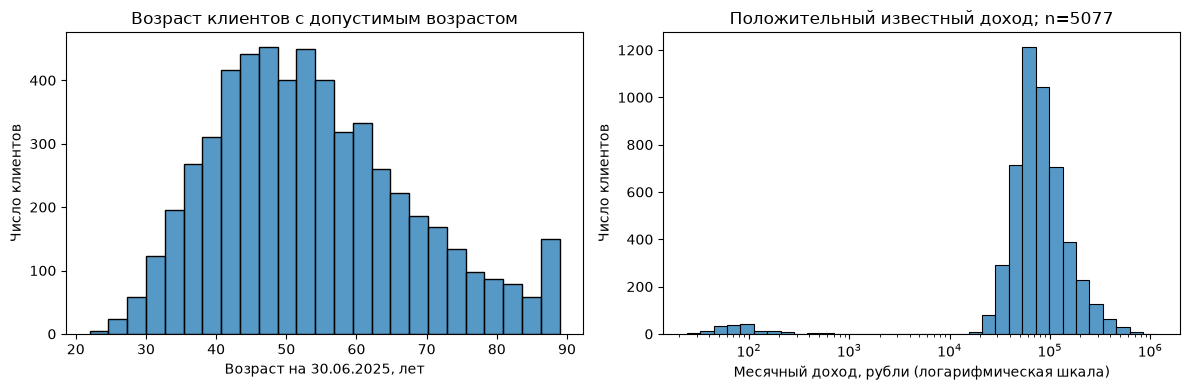

,"Сумма успешной операции, RUB"
count,560707.000000
mean,1851.638942
std,2563.450224
min,3.200000
25%,472.340000
50%,1060.120000
75%,2224.475000
95%,6241.521000
99%,12231.364600
max,207481.450000


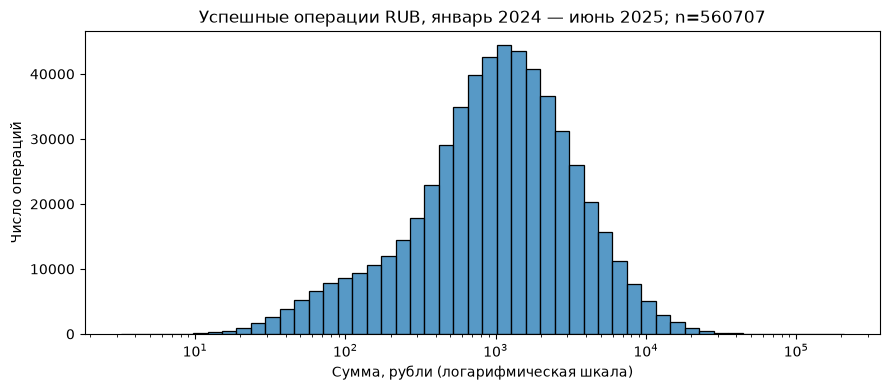

In [14]:
# Среднее чувствительно к большим значениям; медиана и квартили устойчивее.
# Оценка удовлетворённости — порядковая шкала, среднее по ней не считаем.
num_summary = clients[["age", "monthly_income"]].describe(percentiles=[.25, .5, .75, .95, .99]).T
num_summary["IQR"] = num_summary["75%"] - num_summary["25%"]
display(num_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(clients.loc[~clients.age_suspect, "age"].dropna(), bins=25, ax=axes[0])
axes[0].set(xlabel="Возраст на 30.06.2025, лет", ylabel="Число клиентов",
            title="Возраст клиентов с допустимым возрастом")
income = clients.monthly_income.dropna()
income = income[income > 0]
sns.histplot(income.astype(float), bins=35, log_scale=True, ax=axes[1])
axes[1].set(xlabel="Месячный доход, рубли (логарифмическая шкала)", ylabel="Число клиентов",
            title=f"Положительный известный доход; n={len(income)}")
plt.tight_layout(); plt.show()

# Суммы показываем отдельно для RUB, чтобы не смешивать валюты.
rub_amount = activity_txn.loc[activity_txn.currency.eq("RUB"), "amount"].astype(float)
display(rub_amount.describe(percentiles=[.25, .5, .75, .95, .99]).to_frame("Сумма успешной операции, RUB"))
plt.figure(figsize=(9, 4))
sns.histplot(rub_amount, bins=50, log_scale=True)
plt.xlabel("Сумма, рубли (логарифмическая шкала)"); plt.ylabel("Число операций")
plt.title(f"Успешные операции RUB, январь 2024 — июнь 2025; n={len(rub_amount)}")
plt.tight_layout(); plt.show()


### 5.2. Частотные характеристики категориальных признаков

segment — знаменатель: 5641 клиентов


,n_clients,pct_clients
segment,,
Массовый,2870,50.877504
Зарплатный,1668,29.569225
Премиальный,882,15.635526
Private,210,3.722744
Неизвестно (конфликт),11,0.195001


loyalty_tier — знаменатель: 5641 клиентов


,n_clients,pct_clients
loyalty_tier,,
Базовый,2865,50.788867
Серебро,1524,27.016486
Золото,930,16.486439
Платина,322,5.708208


card_type — знаменатель: 5641 клиентов


,n_clients,pct_clients
card_type,,
Дебетовая,3922,69.52668
Кредитная,1273,22.566921
Премиальная,446,7.9064


... (6 outputs left out)

,n_respondents,pct_respondents
satisfaction_score,,
1,275,12.195122
2,452,20.044346
3,428,18.980044
4,461,20.443459
5,639,28.337029


Знаменатель оценок — ответившие: 2255 из 5641 клиентов


,n_transactions,pct_transactions
channel,,
Карта,289971,51.507088
СБП,98611,17.516115
Токен,91603,16.271295
Онлайн-банк,82788,14.705501


,n_transactions,pct_transactions
category,,
Продукты,149279,26.516192
Кафе и рестораны,72480,12.874507
Транспорт,64818,11.513518
Одежда и обувь,57272,10.173134
АЗС,52056,9.246625
Связь и интернет,44195,7.850288
Развлечения и досуг,42336,7.520076
Аптеки,41207,7.319534
Онлайн-сервисы,39330,6.986125


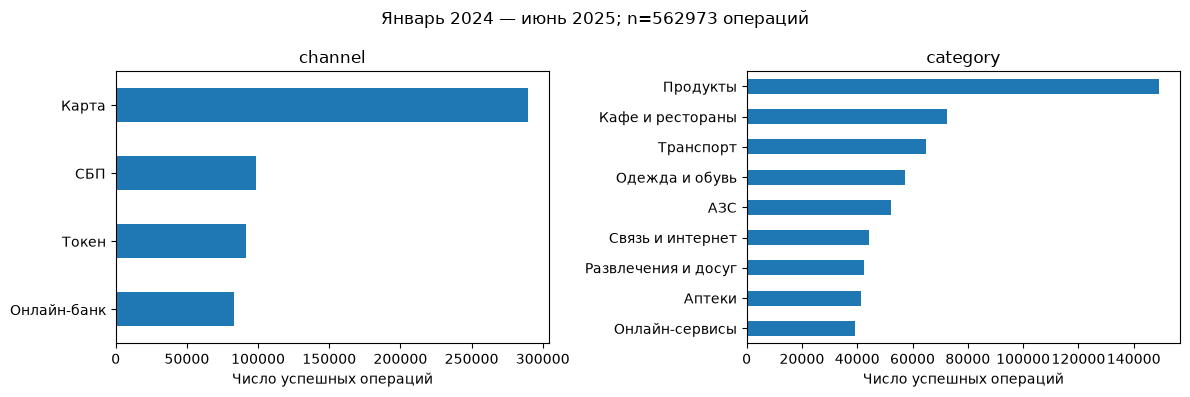

In [15]:
# Знаменатель долей клиентов — весь очищенный справочник.
for field in ["segment", "loyalty_tier", "card_type", "city", "has_mobile_app", "marketing_opt_in"]:
    counts = clients[field].value_counts(dropna=False)
    print(field, "— знаменатель:", len(clients), "клиентов")
    display(pd.DataFrame({"n_clients": counts, "pct_clients": counts / len(clients) * 100}))

# Оценки 1–5 показываем частотами, не средним арифметическим.
score_counts = clients.satisfaction_score.value_counts().sort_index()
display(pd.DataFrame({"n_respondents": score_counts,
                     "pct_respondents": score_counts / score_counts.sum() * 100}))
print("Знаменатель оценок — ответившие:", score_counts.sum(), "из", len(clients), "клиентов")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for field, ax in zip(["channel", "category"], axes):
    counts = activity_txn[field].value_counts()
    display(pd.DataFrame({"n_transactions": counts, "pct_transactions": counts / len(activity_txn) * 100}))
    counts.sort_values().plot.barh(ax=ax)
    ax.set(xlabel="Число успешных операций", ylabel="", title=field)
fig.suptitle(f"Январь 2024 — июнь 2025; n={len(activity_txn)} операций")
plt.tight_layout(); plt.show()


### 5.3. Динамика по месяцам

,all_operations,cohort_operations,cohort_active_clients,operations_per_cohort_client
2024-01,23910,23910,4633,4.349645
2024-02,29580,29580,4712,5.381117
2024-03,33982,33982,4741,6.181917
2024-04,33133,33133,4735,6.027470
2024-05,30591,30591,4725,5.565035
2024-06,32646,32646,4723,5.938876
2024-07,34206,34206,4774,6.222667
2024-08,35353,35319,4825,6.425141
2024-09,33702,33659,4879,6.123158
2024-10,34970,34876,4947,6.344552


Справочник: 5641 клиентов; сопоставимая когорта: 5497
Вне когорты (поздняя или неизвестная регистрация): 144


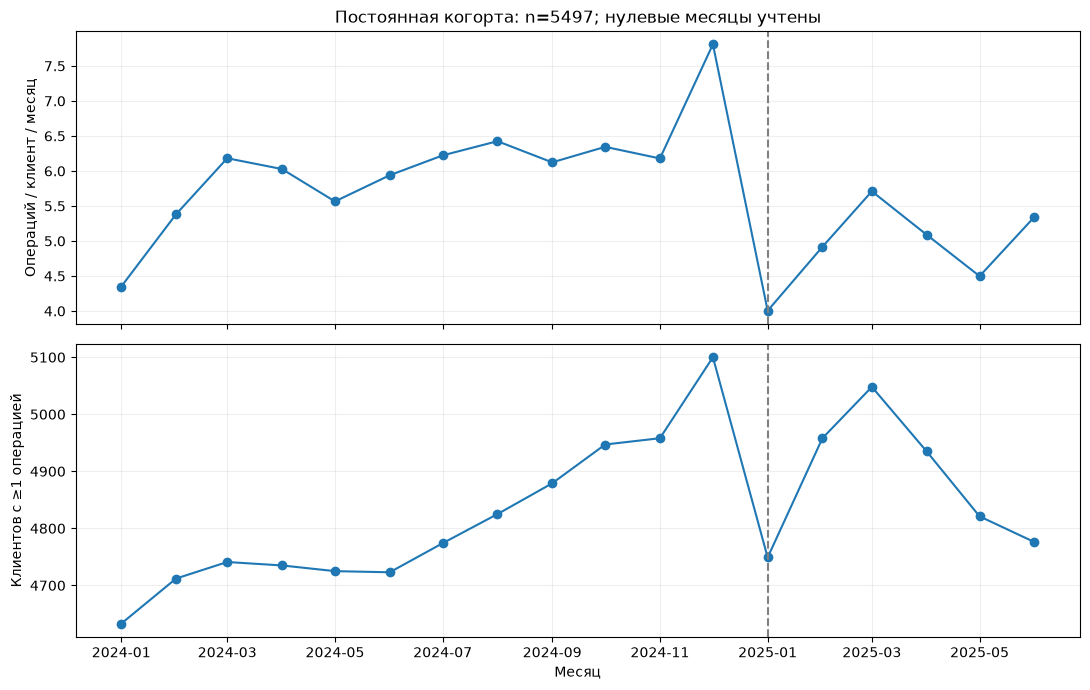

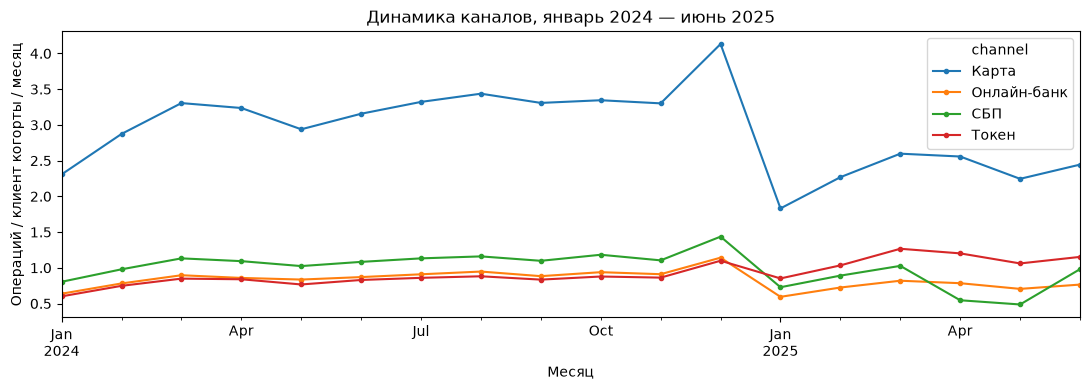

In [16]:
# Фиксируем рабочее определение: число успешных положительных операций в месяц.
# В разделе 6 формально обоснуем метрику и её ограничения.
months = pd.period_range("2024-01", "2025-06", freq="M")
activity_txn["month"] = activity_txn.txn_datetime.dt.to_period("M")
monthly_counts = pd.crosstab(activity_txn.client_id, activity_txn.month).reindex(
    index=clients.client_id, columns=months, fill_value=0)
monthly_counts.index.name = "client_id"
assert monthly_counts.shape == (len(clients), 18)
assert monthly_counts.to_numpy().sum() == len(activity_txn)

# Для сравнения год/полугодие берём клиентов, зарегистрированных до начала базы.
# Новых клиентов сохраняем в общей динамике, но не сравниваем с неполным 2024 годом.
cohort_ids = clients.loc[clients.registration_date.le("2024-01-01"), "client_id"]
cohort_monthly = monthly_counts.loc[cohort_ids]
assert len(cohort_monthly) > 0
trend = pd.DataFrame({
    "all_operations": monthly_counts.sum(),
    "cohort_operations": cohort_monthly.sum(),
    "cohort_active_clients": cohort_monthly.gt(0).sum(),
    "operations_per_cohort_client": cohort_monthly.mean(),
})
display(trend)
print("Справочник:", len(clients), "клиентов; сопоставимая когорта:", len(cohort_ids))
print("Вне когорты (поздняя или неизвестная регистрация):", len(clients)-len(cohort_ids))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
x = months.to_timestamp()
axes[0].plot(x, trend.operations_per_cohort_client, marker="o")
axes[0].set(ylabel="Операций / клиент / месяц", title=f"Постоянная когорта: n={len(cohort_ids)}; нулевые месяцы учтены")
axes[1].plot(x, trend.cohort_active_clients, marker="o")
axes[1].set(ylabel="Клиентов с ≥1 операцией", xlabel="Месяц")
for ax in axes:
    ax.axvline(pd.Timestamp("2025-01-01"), color="gray", linestyle="--")
    ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

# Разложение динамики по каналам на той же фиксированной когорте.
cohort_txn = activity_txn.loc[activity_txn.client_id.isin(cohort_ids)].copy()
channel_monthly = pd.crosstab(cohort_txn.month, cohort_txn.channel).reindex(months, fill_value=0)
channel_monthly.index = channel_monthly.index.to_timestamp()
(channel_monthly / len(cohort_ids)).plot(figsize=(11, 4), marker=".")
plt.ylabel("Операций / клиент когорты / месяц"); plt.xlabel("Месяц")
plt.title("Динамика каналов, январь 2024 — июнь 2025")
plt.tight_layout(); plt.show()


### 5.4. Разрезы и связи между признаками

Сопоставимых клиентов с ненулевой базой: 5183
segment — доля снизивших активность внутри каждой группы


,n_clients,base_mean,current_mean,median_drop_pct,declined_pct,aggregate_drop_pct
segment,,,,,,
Private,189,8.08,6.83,14.06,66.67,15.50
Зарплатный,1517,7.01,6.45,7.14,57.68,7.90
Массовый,2674,5.65,3.80,32.08,77.90,32.71
Неизвестно (конфликт),10,4.88,3.87,20.24,70.00,20.68
Премиальный,793,7.46,6.83,7.14,57.38,8.40


loyalty_tier — доля снизивших активность внутри каждой группы


,n_clients,base_mean,current_mean,median_drop_pct,declined_pct,aggregate_drop_pct
loyalty_tier,,,,,,
Базовый,2647,6.06,4.59,23.29,72.61,24.25
Золото,846,6.84,6.21,8.76,58.75,9.18
Платина,288,7.05,6.14,12.00,63.19,12.84
Серебро,1402,6.69,5.37,17.78,67.40,19.68


has_mobile_app — доля снизивших активность внутри каждой группы


,n_clients,base_mean,current_mean,median_drop_pct,declined_pct,aggregate_drop_pct
has_mobile_app,,,,,,
Да,3199,6.62,5.61,13.73,65.46,15.31
Нет,1984,6.07,4.42,27.94,73.19,27.24


card_type — доля снизивших активность внутри каждой группы


,n_clients,base_mean,current_mean,median_drop_pct,declined_pct,aggregate_drop_pct
card_type,,,,,,
Дебетовая,3616,6.28,4.95,20.00,69.69,21.12
Кредитная,1172,6.59,5.35,16.76,67.66,18.77
Премиальная,395,7.14,6.42,10.24,58.99,10.12


city — доля снизивших активность внутри каждой группы


,n_clients,base_mean,current_mean,median_drop_pct,declined_pct,aggregate_drop_pct
city,,,,,,
Екатеринбург,652,6.36,5.17,15.31,67.18,18.77
Казань,829,6.07,4.32,27.71,76.72,28.94
Москва,1503,6.46,5.28,16.42,66.40,18.21
Неизвестно (конфликт),12,5.51,3.56,20.71,83.33,35.44
Нижний Новгород,668,6.43,5.38,13.83,64.22,16.27
Новосибирск,616,6.50,5.38,18.43,68.34,17.13
Санкт-Петербург,903,6.63,5.39,17.07,68.00,18.65


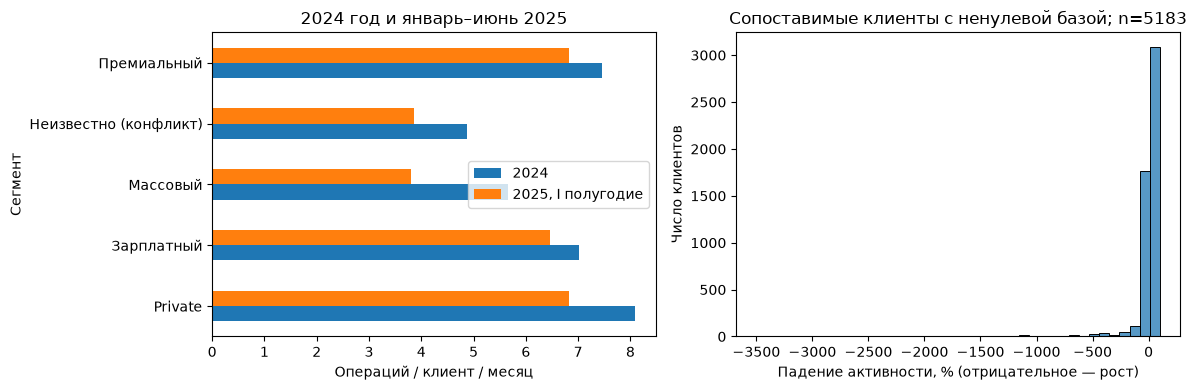

channel — операций в месяц во всей постоянной когорте


txn_datetime,2024,2025,base_per_month,current_per_month,loss_per_month,drop_pct
channel,,,,,,
Карта,212522,76647,17710.17,12774.50,4935.67,27.87
СБП,72717,25612,6059.75,4268.67,1791.08,29.56
Онлайн-банк,58319,24140,4859.92,4023.33,836.58,17.21
Токен,55234,36098,4602.83,6016.33,-1413.50,-30.71


category — операций в месяц во всей постоянной когорте


txn_datetime,2024,2025,base_per_month,current_per_month,loss_per_month,drop_pct
category,,,,,,
Продукты,105259,43581,8771.58,7263.50,1508.08,17.19
Транспорт,48408,16251,4034.00,2708.50,1325.50,32.86
Кафе и рестораны,50671,21589,4222.58,3598.17,624.42,14.79
Одежда и обувь,40178,16921,3348.17,2820.17,528.00,15.77
Связь и интернет,31376,12670,2614.67,2111.67,503.00,19.24
АЗС,36573,15337,3047.75,2556.17,491.58,16.13
Аптеки,29307,11775,2442.25,1962.50,479.75,19.64
Развлечения и досуг,29531,12655,2460.92,2109.17,351.75,14.29
Онлайн-сервисы,27489,11718,2290.75,1953.00,337.75,14.74


Снижение 2025 H1 относительно среднего 2024 года, %: 18.51
Снижение 2025 H1 относительно 2024 H1, %: 11.61


In [17]:
# Таблица метрик: одна строка — один клиент, включая клиентов без операций.
client_metrics = clients.set_index("client_id").copy()
client_metrics["base_per_month"] = monthly_counts.loc[:, "2024-01":"2024-12"].sum(axis=1) / 12
client_metrics["current_per_month"] = monthly_counts.loc[:, "2025-01":"2025-06"].sum(axis=1) / 6
client_metrics["base_h1_per_month"] = monthly_counts.loc[:, "2024-01":"2024-06"].sum(axis=1) / 6
client_metrics["absolute_drop"] = client_metrics.base_per_month - client_metrics.current_per_month
# При нулевой базе процент падения не определён: не заменяем его нулём.
client_metrics["drop_pct"] = (100 * client_metrics.absolute_drop /
    client_metrics.base_per_month.replace(0, np.nan))
client_metrics["comparable"] = client_metrics.index.isin(cohort_ids) & client_metrics.base_per_month.gt(0)
analysis_clients = client_metrics.loc[client_metrics.comparable].copy()
analysis_clients["declined"] = analysis_clients.absolute_drop.gt(0)
print("Сопоставимых клиентов с ненулевой базой:", len(analysis_clients))

segment_tables = {}
for field in ["segment", "loyalty_tier", "has_mobile_app", "card_type", "city"]:
    summary = analysis_clients.groupby(field, dropna=False).agg(
        n_clients=("declined", "size"),
        base_mean=("base_per_month", "mean"), current_mean=("current_per_month", "mean"),
        median_drop_pct=("drop_pct", "median"),
        declined_pct=("declined", lambda s: s.mean()*100))
    summary["aggregate_drop_pct"] = 100*(1-summary.current_mean/summary.base_mean)
    segment_tables[field] = summary
    print(field, "— доля снизивших активность внутри каждой группы")
    display(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
segment_tables["segment"][["base_mean", "current_mean"]].plot.barh(ax=axes[0])
axes[0].set(xlabel="Операций / клиент / месяц", ylabel="Сегмент", title="2024 год и январь–июнь 2025")
axes[0].legend(["2024", "2025, I полугодие"])
sns.histplot(analysis_clients.drop_pct, bins=40, ax=axes[1])
axes[1].set(xlabel="Падение активности, % (отрицательное — рост)", ylabel="Число клиентов",
            title=f"Сопоставимые клиенты с ненулевой базой; n={len(analysis_clients)}")
plt.tight_layout(); plt.show()

# Разложение изменения: каналы и категории могут пересекаться у одного клиента.
breakdown_tables = {}
for field in ["channel", "category"]:
    counts = pd.crosstab(cohort_txn[field], cohort_txn.txn_datetime.dt.year).reindex(columns=[2024, 2025], fill_value=0)
    counts["base_per_month"] = counts[2024]/12
    counts["current_per_month"] = counts[2025]/6
    counts["loss_per_month"] = counts.base_per_month-counts.current_per_month
    counts["drop_pct"] = 100*counts.loss_per_month/counts.base_per_month.replace(0, np.nan)
    breakdown_tables[field] = counts
    print(field, "— операций в месяц во всей постоянной когорте")
    display(counts.sort_values("loss_per_month", ascending=False).round(2))

# Проверка чувствительности к сезонности: сравнение одинаковых полугодий.
base_h1 = cohort_monthly.loc[:, "2024-01":"2024-06"].to_numpy().sum()/6
current_h1 = cohort_monthly.loc[:, "2025-01":"2025-06"].to_numpy().sum()/6
base_year = cohort_monthly.loc[:, "2024-01":"2024-12"].to_numpy().sum()/12
print("Снижение 2025 H1 относительно среднего 2024 года, %:", round(100*(1-current_h1/base_year), 2))
print("Снижение 2025 H1 относительно 2024 H1, %:", round(100*(1-current_h1/base_h1), 2))
# Совпадение направления усиливает устойчивость наблюдения, но не доказывает причину.


## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.
Метрика — число успешных положительных операций за месяц, по всем валютам и каналам. Нулевые месяцы учитываются. Суммы валют не складываем. Для сравнения используем фиксированную когорту зарегистрированных до 01.01.2024. Метрика не видит падение среднего чека, расходов и доходности. Справочник содержит только действующих клиентов на 30.06.2025, поэтому выводы не описывают всех исторических клиентов банка. Причины поведения и эффективность будущей кампании не наблюдаются.


In [18]:
# Основная метрика уже рассчитана в 5.4: успешные операции за период / число месяцев.
# Число операций не зависит от валюты и устойчиво к большим суммам отдельных покупок.
# Но не видит падения среднего чека, расходов или доходности банка.
# База: январь–декабрь 2024 (12 месяцев); оценка: январь–июнь 2025 (6 месяцев).
# Сравниваем зарегистрированных до 2024 года; нулевые месяцы включены.
metric_summary = pd.DataFrame({
    "period": ["2024", "2025 H1"],
    "months": [12, 6],
    "operations_per_month": [base_year, current_h1],
    "clients_in_fixed_cohort": [len(cohort_ids), len(cohort_ids)],
})
display(metric_summary)
print("Общее падение, %:", round(100*(1-current_h1/base_year), 2))
# Для кампании: не менее 20% и не менее 1 операции в месяц.
# Это практический порог существенности, не статистический тест и не оптимизация отклика.


,period,months,operations_per_month,clients_in_fixed_cohort
0,2024,12,33232.666667,5497
1,2025 H1,6,27082.833333,5497


Общее падение, %: 18.51


## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

In [19]:
# Признаки каналов: сколько операций в месяц было и стало у каждого клиента.
channels = ["Карта", "СБП", "Токен", "Онлайн-банк"]
for channel in channels:
    channel_counts = activity_txn.loc[activity_txn.channel.eq(channel)].groupby(
        ["client_id", activity_txn.txn_datetime.dt.year]).size().unstack(fill_value=0)
    channel_counts = channel_counts.reindex(index=client_metrics.index, columns=[2024, 2025], fill_value=0)
    client_metrics[channel + "_base"] = channel_counts[2024]/12
    client_metrics[channel + "_now"] = channel_counts[2025]/6
    client_metrics[channel + "_loss"] = client_metrics[channel + "_base"]-client_metrics[channel + "_now"]
loss_columns = [channel + "_loss" for channel in channels]
# Если потери равны, приоритет: Карта, СБП, Токен, Онлайн-банк (порядок списка).
client_metrics["main_loss_channel"] = client_metrics[loss_columns].idxmax(axis=1).str.replace("_loss", "", regex=False)
client_metrics["eligible"] = (client_metrics.comparable & client_metrics.marketing_opt_in.eq("Да")
    & client_metrics.drop_pct.ge(20) & client_metrics.absolute_drop.ge(1))

# Каждая группа: пользователи определённого канала с наибольшим падением в нём.
group_names = {"Карта": "G1_Карта", "СБП": "G2_СБП", "Токен": "G3_Токен"}
client_metrics["group"] = ""
for channel, group in group_names.items():
    mask = client_metrics.eligible & client_metrics.main_loss_channel.eq(channel)
    client_metrics.loc[mask, "group"] = group
campaign = client_metrics.loc[client_metrics.group.ne("")].reset_index()[["client_id", "group"]]
# Для новой выгрузки при превышении бюджета ранжируем по потерянным операциям,
# затем по ID; в текущей выгрузке сокращение не требуется.
if len(campaign) > 2000:
    ranked = client_metrics.loc[client_metrics.group.ne("")].reset_index().sort_values(
        ["absolute_drop", "client_id"], ascending=[False, True]).head(2000)
    campaign = ranked[["client_id", "group"]].copy()
    client_metrics.loc[~client_metrics.index.isin(campaign.client_id), "group"] = ""
assert campaign.client_id.is_unique
assert len(campaign) <= 2000
assert campaign.group.nunique() == 3
assert campaign.group.value_counts().ge(150).all(), "Для новой выгрузки пересмотрите правила: группа меньше 150"
assert client_metrics.loc[campaign.client_id, "marketing_opt_in"].eq("Да").all()

group_summary = client_metrics.loc[campaign.client_id].groupby("group").agg(
    n_clients=("group", "size"), base_mean=("base_per_month", "mean"),
    current_mean=("current_per_month", "mean"), median_drop_pct=("drop_pct", "median"))
group_summary["aggregate_drop_pct"] = 100*(1-group_summary.current_mean/group_summary.base_mean)
for channel, group in group_names.items():
    part = client_metrics.loc[client_metrics.group.eq(group)]
    group_summary.loc[group, "main_channel_loss_per_month"] = part[channel+"_loss"].sum()
    group_summary.loc[group, "total_loss_per_month"] = part.absolute_drop.sum()
display(group_summary.round(2))
# Исследовательские разрезы пересекаются: один клиент может снижать несколько каналов.
print("Отобранных клиентов со снижением в нескольких каналах:",
      client_metrics.loc[campaign.client_id, loss_columns].gt(0).sum(axis=1).ge(2).sum())
print("В кампании:", len(campaign))


,n_clients,base_mean,current_mean,median_drop_pct,aggregate_drop_pct,main_channel_loss_per_month,total_loss_per_month
group,,,,,,,
G1_Карта,1454,6.80,3.30,56.52,51.52,3710.58,5091.33
G2_СБП,280,6.69,3.66,43.34,45.34,591.67,849.83
G3_Токен,190,7.36,3.56,55.56,51.65,423.17,722.25


Отобранных клиентов со снижением в нескольких каналах: 1908
В кампании: 1924


### 7.1. Кого в кампанию не берём и почему

In [20]:
# Взаимоисключающие причины: присваиваем первую подходящую по порядку.
client_metrics["exclusion"] = "В кампании"
remaining = pd.Series(True, index=client_metrics.index)
exclusion_rules = [
    ("Нет согласия", ~client_metrics.marketing_opt_in.eq("Да")),
    ("Неполный/неизвестный базовый период", ~client_metrics.registration_date.le("2024-01-01")),
    ("Нет активности в базе", client_metrics.base_per_month.eq(0)),
    ("Нет падения >=20% и >=1 операции/месяц", ~(client_metrics.drop_pct.ge(20) & client_metrics.absolute_drop.ge(1))),
    ("Основная потеря в Онлайн-банке или лимит", client_metrics.group.eq("")),
]
for reason, mask in exclusion_rules:
    selected = remaining & mask
    client_metrics.loc[selected, "exclusion"] = reason
    remaining = remaining & ~selected
exclusions = client_metrics.exclusion.value_counts().rename_axis("reason").to_frame("n_clients")
assert exclusions.n_clients.sum() == len(clients)
display(exclusions)
# Онлайн-банк не включаем: после разрешения пересечений группа меньше 150.


,n_clients
reason,
Нет падения >=20% и >=1 операции/месяц,2497
В кампании,1924
Нет согласия,687
Нет активности в базе,276
Основная потеря в Онлайн-банке или лимит,136
Неполный/неизвестный базовый период,121


## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

In [21]:
# Неподтвердившиеся предположения и проверки устойчивости.
hypotheses = pd.DataFrame([
    {"hypothesis": "Все каналы падают", "result": "Не подтвердилось: токен растёт", "value_pct": -breakdown_tables["channel"].loc["Токен", "drop_pct"]},
    {"hypothesis": "Сегменты снижаются одинаково", "result": "Массовый сегмент: падение", "value_pct": segment_tables["segment"].loc["Массовый", "aggregate_drop_pct"]},
    {"hypothesis": "Сегменты снижаются одинаково", "result": "Зарплатный сегмент: падение", "value_pct": segment_tables["segment"].loc["Зарплатный", "aggregate_drop_pct"]},
    {"hypothesis": "Падение исчезнет при одинаковых полугодиях", "result": "Падение H1 2025 к H1 2024 сохраняется", "value_pct": 100*(1-current_h1/base_h1)},
])
display(hypotheses.round(2))
# Проверяем, не создают ли вывод единичные огромные операции.
q99 = activity_txn.loc[activity_txn.currency.eq("RUB"), "amount"].quantile(.99)
without_large = cohort_txn.loc[~(cohort_txn.currency.eq("RUB") & cohort_txn.amount.gt(q99))]
year_counts = without_large.groupby(without_large.txn_datetime.dt.year).size()
sensitivity = {"full_drop_pct": 100*(1-current_h1/base_year),
    "without_top1_rub_drop_pct": 100*(1-(year_counts[2025]/6)/(year_counts[2024]/12)),
    "same_halfyear_drop_pct": 100*(1-current_h1/base_h1)}
print("Чувствительность к крупным операциям:", sensitivity)

# Дополнительные проверки после сверки полноты анализа с внешним примером.
# Используем только свой набор S31; чужие числа и правила не переносим.
full_card = (client_metrics.registration_date.le("2024-01-01")
             & client_metrics.card_open_date.lt("2024-01-01"))
card_cohort = client_metrics.loc[full_card]
card_drop = 100*(1-card_cohort.current_per_month.sum()/card_cohort.base_per_month.sum())
print("Карта открыта до 2024: клиентов", len(card_cohort), "падение, %", round(card_drop, 2))
print("Карт с открытием с 2024 года в выбранной кампании:",
      client_metrics.loc[campaign.client_id, "card_open_date"].ge("2024-01-01").sum())
# Общая динамика включает клиентов с поздним открытием карты; это влияет на величину.
# Проверка на старых картах подтверждает направление, а не равенство оценок.
before_card = activity_txn.txn_datetime.lt(activity_txn.client_id.map(client_metrics.card_open_date))
print("Операций до открытия текущей карты:", before_card.sum())
display(activity_txn.loc[before_card, ["txn_id", "client_id", "txn_datetime"]])
# Единичная запись требует проверки источника; нет основания исправлять её дату.

threshold_rows = []
for threshold in [15, 20, 25]:
    condition = (client_metrics.comparable & client_metrics.marketing_opt_in.eq("Да")
        & client_metrics.drop_pct.ge(threshold) & client_metrics.absolute_drop.ge(1)
        & client_metrics.main_loss_channel.isin(group_names))
    candidates = client_metrics.loc[condition].reset_index().sort_values(
        ["absolute_drop", "client_id"], ascending=[False, True])
    chosen = candidates.head(2000)
    sizes = chosen.main_loss_channel.value_counts()
    threshold_rows.append({"threshold_pct": threshold, "before_budget": len(candidates),
        "after_budget": len(chosen), **{ch: int(sizes.get(ch, 0)) for ch in group_names}})
threshold_check = pd.DataFrame(threshold_rows)
display(threshold_check)

# Отказы: знаменатель — попытки (успешные + отклонённые), без возвратов.
attempts = txn.loc[txn.client_id.isin(campaign.client_id)
    & txn.txn_datetime.ge("2024-01-01") & txn.txn_datetime.lt("2025-07-01")
    & txn.status.isin(["успешно", "отклонено"])].copy()
attempts["declined"] = attempts.status.eq("отклонено")
rejection_check = attempts.groupby(attempts.txn_datetime.dt.year).agg(
    attempts=("txn_id", "size"), declined=("declined", "sum"),
    declined_pct=("declined", lambda s: s.mean()*100))
display(rejection_check)
# Небольшой рост доли отказов не доказывает техническую причину общего снижения.


,hypothesis,result,value_pct
0,Все каналы падают,Не подтвердилось: токен растёт,30.71
1,Сегменты снижаются одинаково,Массовый сегмент: падение,32.71
2,Сегменты снижаются одинаково,Зарплатный сегмент: падение,7.90
3,Падение исчезнет при одинаковых полугодиях,Падение H1 2025 к H1 2024 сохраняется,11.61


Чувствительность к крупным операциям: {'full_drop_pct': np.float64(18.505386266524905), 'without_top1_rub_drop_pct': np.float64(18.448299011250423), 'same_halfyear_drop_pct': np.float64(11.610513375616016)}
Карта открыта до 2024: клиентов 4817 падение, % 21.27
Карт с открытием с 2024 года в выбранной кампании: 0


Операций до открытия текущей карты: 1


,txn_id,client_id,txn_datetime
234419,990187,C000834,2024-07-25 08:45:00


,threshold_pct,before_budget,after_budget,Карта,СБП,Токен
0,15,2058,2000,1503,298,199
1,20,1924,1924,1454,280,190
2,25,1746,1746,1328,240,178


,attempts,declined,declined_pct
txn_datetime,,,
2024,160913,3054,1.89792
2025,39837,888,2.229084


## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [22]:
# CSV выбран для простоты: не нужна дополнительная библиотека parquet.
from pathlib import Path
import json
Path("results").mkdir(exist_ok=True)
client_metrics.reset_index().to_csv("results/clean_clients_metrics.csv", index=False)
activity_txn.to_csv("results/clean_transactions.csv", index=False)
monthly_counts.rename(columns=str).to_csv("results/monthly_counts.csv")
group_summary.to_csv("results/group_summary.csv")
exclusions.to_csv("results/exclusions.csv")
trend.to_csv("results/trend.csv")
for field, table in breakdown_tables.items():
    table.to_csv("results/breakdown_" + field + ".csv")
hypotheses.to_csv("results/hypotheses.csv", index=False)
with open("results/sensitivity.json", "w") as f:
    json.dump(sensitivity, f)
cleaning_log = pd.DataFrame(log_rows)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8-sig")
campaign.to_csv("campaign_list.csv", index=False, encoding="utf-8-sig")
print("Сохранены очищенные таблицы, метрики, журнал и список кампании.")

threshold_check.to_csv("results/threshold_check.csv", index=False)
rejection_check.to_csv("results/rejection_check.csv")


Сохранены очищенные таблицы, метрики, журнал и список кампании.
